# Air hockey puck: C physics, a terminal game, and a CUDA renderer

| File | What it is |
|---|---|
| `dgs/c/puck/puck.h`, `puck.c` | C99 physics: **statics** (inertia, the air pressure that balances the weight), **dynamics** (drag, wall bounces, goal), and a 2-D **rotation matrix** |
| `dgs/c/puck/puck_test.c` | CSC 60 style tests: a `CHECK` macro, one function per behavior, exit code = number of failures |
| `dgs/c/puck/puck_game.c`, `Makefile` | a terminal mini game: `make test`, then `./puck_game` |
| `dgs/cuda/puck_render.cu` | one GPU thread per pixel: rotate each ray into the puck's frame with Mᵀ, hit the cylinder, shade with M n |

Everything compiles with `-std=c99 -Wall -Wextra -pedantic -Werror`.

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, matplotlib.pyplot as plt
from dgs import puck_game as P
from dgs.eventsim import ToolUnavailable

## 1. Statics and the C unit tests

**Statics** means the forces balance. A floating puck has the air pressure under its face
holding up its weight: p·πR² = Mg, so p = Mg/(πR²). For a 17 g puck with a 6.5 cm face that's
about 50 Pa, or 0.05% of atmospheric pressure.

In [2]:
try:
    passed, total, out = P.run_c_tests(); print(out)
except ToolUnavailable as err:
    print("skipped:", err)

11/11 checks passed



## 2. Dynamics: the mini game

Each step updates the velocity with drag, then the position (semi-implicit Euler), then
reflects off the walls with restitution e = 0.9. The `*` is a spin marker placed by the
rotation matrix `rot2(theta, ...)`.

In [3]:
try:
    for shot in [(0, 3.0, 40), (12, 2.6, 15), (35, 2.5, 10)]:
        scored, board, info = P.play(*shot)
        print(f"angle {shot[0]} deg, {shot[1]} m/s, spin {shot[2]} rad/s ->", info["result"]); print(board, "\n")
except ToolUnavailable as err:
    print("skipped:", err)

angle 0 deg, 3.0 m/s, spin 40 rad/s -> GOAL
------------------------------------------------------------
                                                            
                                                            
                                                            
                                                            
                                                            
                                                           |
                                                        *  |
      .   .  .   .  .  .   .  .   .  .  .   .  .  .   .  .O|
                                                           |
                                                            
                                                            
                                                            
                                                            
                                                            
-----------------------------------------

angle 12 deg, 2.6 m/s, spin 15 rad/s -> stopped
------------------------------------------------------------
                                      . ...............     
                             . . ........             ..... 
                    . . .........          .  .........     
           . . .  ........         .  . ........            
 . . . . .........         . .  ........                    
   ........       .  .  ........                           |
 ......  . .. ............                                 |
      ...........  . . . ..                                |
  .........  ........       . .. . .                       |
 .... ...           ........         .. .. .                
         .......           .O                .. .. .        
                . .......    *                       .. ..  
                          ..... ..               . ... ..   
                                  .. .... .... ..           
-------------------------------------

angle 35 deg, 2.5 m/s, spin 10 rad/s -> stopped
------------------------------------------------------------
  .. ..                  .......             ........       
  ..    ..          . ....   .  ....      ....      ....    
     ...   . .    .....           .........            .... 
         ..   .....                ......              .... 
           .....  ..         * .....  .  ....      ....     
        ....  .. .   . .    O...           . .......       |
     ....         ..    . .                 .......        |
 ....               . ..    .            ....    . ....    |
 ....                   . .  . .     ....          .  ...  |
    ....                   ...   .....                  ... 
       ....                   ....  . .              . .. . 
           ...             ....  ...    .        .... .     
              ...       ...         . .   ..  ...  . .      
                 .......               ..... . . .          
-------------------------------------

## 3. CUDA rendering with linear algebra

The orientation is M = R_x(tilt) R_z(spin). Rotation matrices are orthogonal, so M⁻¹ = Mᵀ: each
camera ray is moved into the puck's own frame with Mᵀ. There the puck is a simple cylinder
x² + y² ≤ R², |z| ≤ h/2. The renderer intersects the caps and the side, then rotates the normal
back with M for Lambert shading.

**Check:** a tilted cylinder's projected area is π|cos t| + 2h|sin t| (with R = 1). The GPU pixel
count has to match that formula.

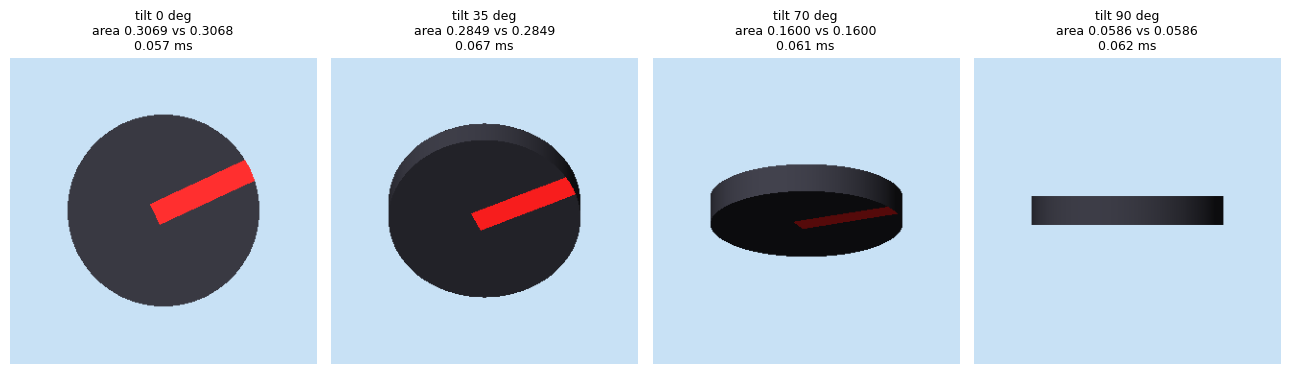

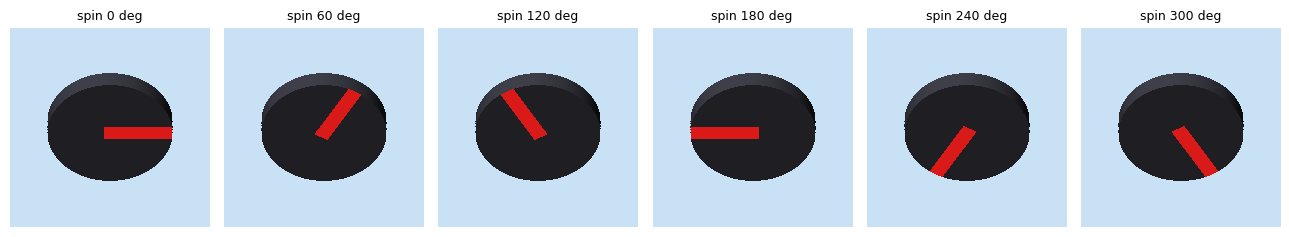

In [4]:
try:
    fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
    for a_, tilt in zip(ax, [0, 35, 70, 90]):
        img, info = P.render(tilt_deg=tilt, spin_deg=25, h_over_R=0.3, size=320)
        frac = info["puck_pixels"] / img.shape[0] / img.shape[1]
        a_.imshow(img); a_.axis("off")
        a_.set_title(f"tilt {tilt} deg\narea {frac:.4f} vs {P.projected_area_fraction(tilt, 0.3):.4f}\n{info['kernel_ms']:.3f} ms", fontsize=9)
    plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(1, 6, figsize=(13, 2.4))
    for a_, spin in zip(ax, range(0, 360, 60)):
        a_.imshow(P.render(tilt_deg=40, spin_deg=spin, size=200)[0]); a_.axis("off"); a_.set_title(f"spin {spin} deg", fontsize=9)
    plt.tight_layout(); plt.show()
except ToolUnavailable as err:
    print("skipped:", err)